In [1]:
import pya
from pya import *
import SiEPIC
from SiEPIC._globals import Python_Env
from SiEPIC.scripts import connect_cell, connect_pins_with_waveguide, zoom_out, export_layout
from SiEPIC.utils import create_cell2, get_layout_variables
from SiEPIC.utils.layout import new_layout, floorplan, coupler_array
from SiEPIC.extend import to_itype
from SiEPIC.verification import layout_check
import numpy as np
from SiEPIC.scripts import connect_pins_with_waveguide, connect_cell
import os
import sys
from SiEPIC.utils import klive

# Generic Imports
import os
import pya
from pya import *
import numpy as np
import pandas as pd
from SiEPIC.utils import klive
from SiEPIC.scripts import connect_pins_with_waveguide, zoom_out, export_layout
from SiEPIC._globals import Python_Env
from SiEPIC.utils.layout import new_layout
import sys
import openpyxl

KLayout SiEPIC-Tools version 0.5.31
SiEPIC-Tools is up to date (0.5.31 vs 0.5.31).
Version check, time: 0.1208345890045166 seconds


In [2]:

if Python_Env == 'Script':

    # Define the path to your local PDK
    path_to_pdk = r"D:\GitHub"
    # path_GitHub = r"C:\Users\gamem\OneDrive - UBC\Documents\GitHub"

    sys.path.insert(0, os.path.join(path_to_pdk, "Shallow_Etch_BTO_PDK","klayout"))

    # Now try importing the PDK
    import Shallow_Etch_BTO



SiEPIC-Shallow_Etch_BTO-PDK Python module: Shallow_Etch_BTO_PDK, KLayout technology: Shallow_Etch_BTO
SiEPIC-Shallow_Etch_BTO-PDK Python module: pymacros
 - Technology path: D:\Github\Shallow_Etch_BTO_PDK\klayout\Shallow_Etch_BTO
 - PCell folder path: D:\Github\Shallow_Etch_BTO_PDK\klayout\Shallow_Etch_BTO\python\pcells_Shallow_Etch_BTO
 - PCell module name: pcells_Shallow_Etch_BTO
 - PCell init file: D:\Github\Shallow_Etch_BTO_PDK\klayout\Shallow_Etch_BTO\python\pcells_Shallow_Etch_BTO\__init__.py
 - imported PCell: pcells_Shallow_Etch_BTO.BTO_ShEtch_CustomTaper
 - imported PCell: pcells_Shallow_Etch_BTO.BTO_ShEtch_dc_halfring_straight
 - imported PCell: pcells_Shallow_Etch_BTO.BTO_ShEtch_spiral_paperclip
 - imported PCell: pcells_Shallow_Etch_BTO.BTO_ShEtch_taper
 - imported PCell: pcells_Shallow_Etch_BTO.BTO_ShEtch_VarBend
 - imported PCell: pcells_Shallow_Etch_BTO.BTO_Universal_GC
 - imported PCell: pcells_Shallow_Etch_BTO.euler_bend_180
 - imported PCell: pcells_Shallow_Etch_BTO.S

In [3]:
tech_name = 'Shallow_Etch_BTO'  # Can change this
gclib_name = 'Shallow_Etch_BTO'
lib_name = 'Shallow_Etch_BTO'

top_cell_name = 'TT'  # Change this to the name of the top cell from the floorplan

chip_name = 'SiEPICfab_bto'  # Change this to the name of the .oas file from the folder gds_floorplan
chip_folder = 'SiEPICfab_bto'


chip_file = os.path.join("gds_floorplan", f"{chip_name}.oas")  # Main chip file in floorplan
layout_file = os.path.join("designs", f"{top_cell_name}.oas")  # Name of the soon-to-be chip


In [4]:
def GDS_Export(topcell,cellname):
    # Export for fabrication, removing PCells
    path = r"D:\Github\SiEPIC-Klayout-in-VSCode\floorplan_btomrr\gds_in"

    file_out = export_layout(topcell, path, cellname, relative_path = '', format='gds', screenshot=True)

    # Display the layout in KLayout, using KLayout Package "klive", which needs to be installed in the KLayout Application
    if Python_Env == 'Script':
        klive.show(file_out, technology=tech_name)

    print('\n COMPLETED \n')

In [5]:
"""
This script is used to extract a cell from a floorplan and save it as a GDS file.
Worry less about it, just run it and it will do the job.
"""

_, _ly = new_layout(tech_name, "test", GUI=True, overwrite = False)
_ly.read(chip_file)
_top_cell = _ly.cell(top_cell_name)
_top_cell.write(layout_file) #save the layout to a GDS file

In [6]:
"""
This script is used to open a GDS file and display it in KLayout.
Creates a new layout and reads the GDS file the above cell made.
"""


_, ly = new_layout(tech_name, "test", GUI=True, overwrite = False)
ly.read(layout_file)
# Access the top cell
top_cell = ly.cell(top_cell_name)

dbu = ly.dbu
wg_bend_radius = 20
              

top_cell.plot() # in the browser
top_cell.show() # in KLayout

Message from klive: {"version": "0.4.1", "klayout_version": "0.29.4", "type": "open", "file": "C:\\Users\\jxs\\AppData\\Local\\Temp\\tmpdo5fbjs7\\TT.gds"}


Message from klive: {"version": "0.4.1", "klayout_version": "0.29.4", "type": "reload", "file": "C:\\Users\\jxs\\AppData\\Local\\Temp\\tmpdo5fbjs7\\TT.gds"}


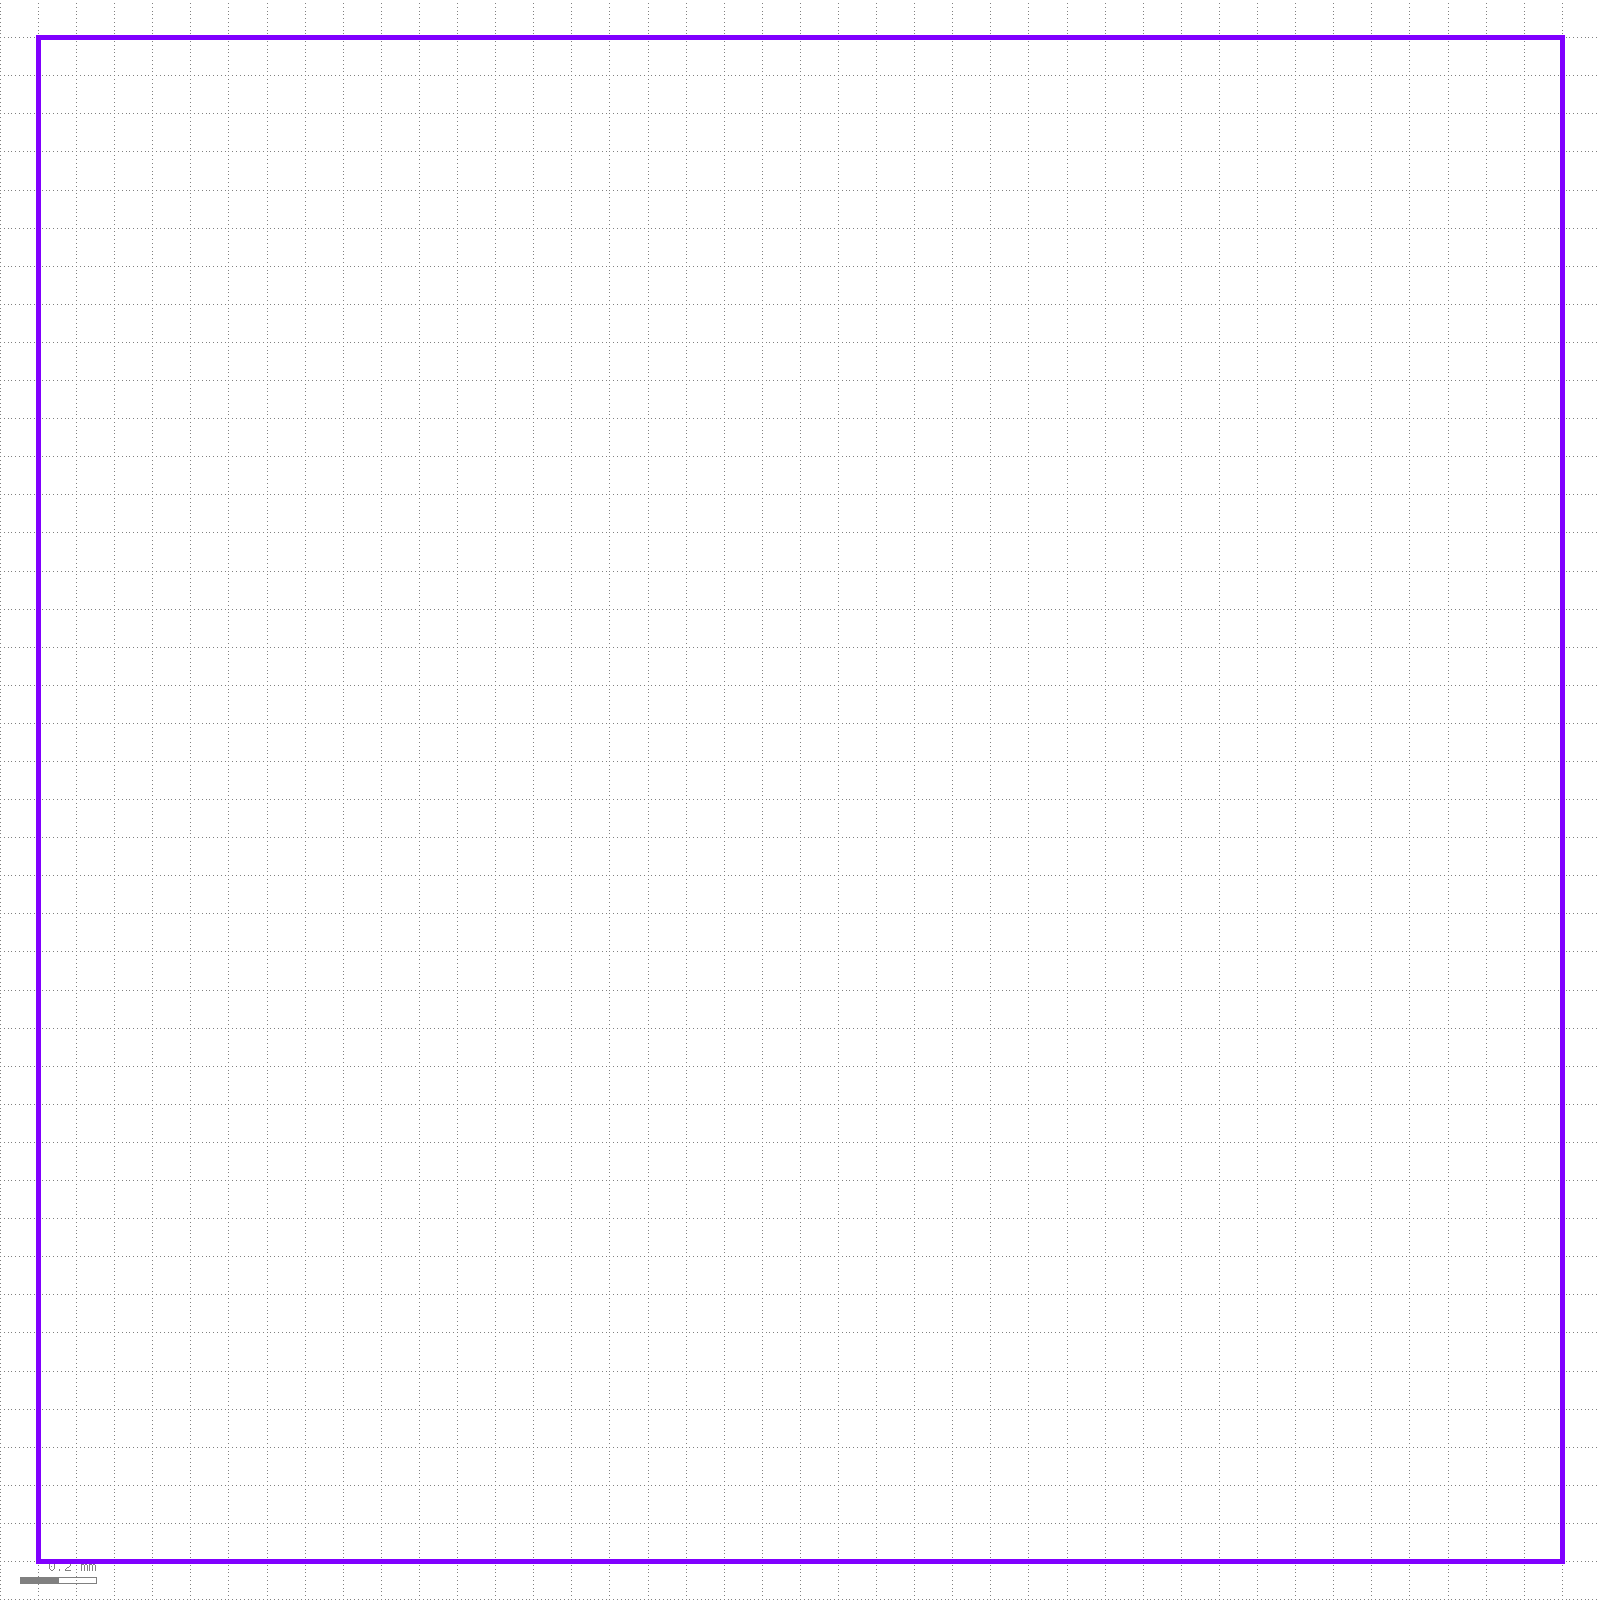

In [7]:
top_cell.bbox().width()*dbu, top_cell.bbox().height()*dbu, top_cell.bbox().right, top_cell.bbox().top # just useful to confirm the size of the cell
# Zoom out
# zoom_out(cell)
top_cell.show() # in KLayout GUI
top_cell.plot() # in the browser

In [8]:
# ============================================================
# Global/default GC settings
# Define once and reuse in later cells
# ============================================================
GC_SETTINGS = {
    "gc_cell_name": "BTO_ShEtch_GC_1550",
    "gc_library": gclib_name,
    "gc_pitch": 127.0,   # microns
    "default_num_gc": 4,
    "label_location": 2,
}

GC_SETTINGS_free = {
    "gc_cell_name": "BTO_Universal_GC",
    "gc_library": gclib_name,
    "gc_pitch": 127.0,   # microns
    "default_num_gc": 4,
    "label_location": 2,
    "parameters": {
        "target_length": 25,
        "duty_cycle": 0.45,
        "pitch": 1.045,
        "radius": 25,
        "y_span": 15,
        "L_extra": 5,
        "wg_width": 1.0,
    }
}

WG_SETTINGS = {
    "wg_type": "Low-loss Bend Waveguide, w=1.0um r=100um",
}
device_prefix = "opt_in_TE_1550_device_XX"

margin_x = 250

In [9]:

def GC_placement(x,y,GC_SETTINGS,ParentCell,angle=0):
    if GC_SETTINGS is None:
    # global GC_SETTINGS
        GC_SETTINGS = globals().get("GC_SETTINGS", None)
        GC_pcell = ly.create_cell(GC_SETTINGS["gc_cell_name"], GC_SETTINGS["gc_library"])

    else:
        GC_SETTINGS = GC_SETTINGS
        GC_pcell = ly.create_cell(GC_SETTINGS["gc_cell_name"], GC_SETTINGS["gc_library"],
                                  {})

    if angle == 0:
        t = pya.Trans(pya.Trans.R0, x + GC_pcell.bbox().width(), y - GC_pcell.bbox().bottom)
    else:
        t = pya.DCplxTrans(1.0, angle, False, x + GC_pcell.bbox().width(), y - GC_pcell.bbox().bottom)
    GC_inst = ParentCell.insert(pya.CellInstArray(GC_pcell.cell_index(), t))
    return GC_pcell, GC_inst

In [ ]:
def place_VarBEnd(inst4connect,instpin,Bendpin,angle1=-90,angle2=-45):
    VB_pcell = ly.create_cell("BTO_ShEtch_VarBend",tech_name,{
            "wg_width": 1,
            "bend_r": 100,
            "angle1": angle1,
            "angle2": angle2,      
        })
    inst_VarBend = connect_cell(inst4connect, instpin, VB_pcell , Bendpin)
    return VB_pcell, inst_VarBend

def VarBend(x,y,ParentCell,angle1=-90,angle2=-45):
    
    VB_pcell = ly.create_cell("BTO_ShEtch_VarBend",tech_name,{
            "wg_width": 1,
            "bend_r": 100,
            "angle1": angle1,
            "angle2": angle2,      
        })
    t = pya.Trans(pya.Trans.R0, x+0.01e3, y - VB_pcell.bbox().bottom - 9.2e3/2)
    VB_inst = ParentCell.insert(pya.CellInstArray(VB_pcell.cell_index(), t))
    return VB_pcell, VB_inst

def SinglePassRacetrackMod(
    x,
    y,
    ParentCell,
    straight_len_um=100,
    gap_um=0.2,
    radius_um=80,
    wg_width_um=1.0,
    angle_deg=45,
    electrode_width_um=5,
    electrode_gap_um=6,
    electrode_clearance_um=2,
    waveguide_type=None,
    electrode_size_um = 210,
    GC_SETTINGS = None
):
    from SiEPIC.utils.layout import make_pin

    dbu = ly.dbu
    if waveguide_type is None:
        waveguide_type = WG_SETTINGS["wg_type"] if "WG_SETTINGS" in globals() else "Low-loss Bend Waveguide, w=1.2um r=100um"
    wg_half = to_itype(wg_width_um / 2+4, dbu)
    wg_wdith = to_itype(wg_width_um, dbu)
    e_w = to_itype(electrode_width_um, dbu)
    e_gap = to_itype(electrode_gap_um, dbu)
    e_clr = to_itype(electrode_clearance_um, dbu)
    straight = to_itype(straight_len_um, dbu)
    electrode_gap = to_itype(electrode_gap_um, dbu)
    electrode_size = to_itype(electrode_size_um, dbu)

    
    gap_tag = str(gap_um).replace(".", "p")
    base_tag = f"R{int(radius_um)}_G{gap_tag}_L{int(straight_len_um)}_A{int(angle_deg)}"

    # 1) Half-rings
    rt_core = ly.create_cell(f"SP_RacetrackCore_{base_tag}")
    rt_wrapper = ly.create_cell(f"SP_RacetrackWrap_{base_tag}_2")

    # angle = 0
    # [GC1_pcell, GC1_inst] = GC_placement(x,y,ParentCell,angle)
    # y+=2*127e3
    # [GC2_pcell, GC2_inst] = GC_placement(x,y,ParentCell,angle)
    # label = pya.Text(f"opt_in_TE_1550_device_RacetrackRing{base_tag}",pya.Trans(pya.Trans.R0, x + GC2_pcell.bbox().width(), y + GC2_pcell.bbox().height()/2))
    # ParentCell.shapes(ly.layer(ly.TECHNOLOGY['Text'])).insert(label)

    # x += GC1_pcell.bbox().width()/2 - 0.01e3
    # y += GC1_pcell.bbox().height()/2 - 9.2e3/2
    # xgc = x; ygc = x

    gc_distance = 3*127e3
    # y -= gc_distance
    # x += 100e3
    
    # Add bend
    x_ring = 0
    y_ring = 0
        

    top_half = ly.create_cell(
        "BTO_ShEtch_dc_halfring_straight",
        tech_name,
        {"r": radius_um, "w": wg_width_um, "g": gap_um, "Lc": 0, "AddDrop": True},
    )
    top_inst = rt_core.insert(pya.CellInstArray(top_half.cell_index(), pya.Trans(pya.Trans.R0, 0, 0)))

    bot_half = ly.create_cell(
        "BTO_ShEtch_dc_halfring_straight",
        tech_name,
        {"r": radius_um, "w": wg_width_um, "g": gap_um, "Lc": 0, "AddDrop": False},
    )

    t_bot = pya.Trans(
        pya.Trans.R180,
        0,
        top_inst.bbox().top + to_itype(wg_width_um, dbu) + straight + bot_half.bbox().height() - to_itype(wg_width_um, dbu),
    )
    bot_inst = rt_core.insert(pya.CellInstArray(bot_half.cell_index(), t_bot))

    # 2) Explicit straight waveguides, positioned by waveguide centerlines
    connect_pins_with_waveguide(top_inst,'pin2',bot_inst,'pin4',waveguide_type=wg)
    connect_pins_with_waveguide(top_inst,'pin4',bot_inst,'pin2',waveguide_type=wg)


    # ring_x_left = top_inst.bbox().left + wg_half
    # ring_x_right = top_inst.bbox().right - wg_half

    # # # Vertical centers where straight sections should connect
    # y_upper_center = top_inst.bbox().top + wg_half
    # y_lower_center = bot_inst.bbox().bottom - wg_half

    # y_start = min(y_upper_center, y_lower_center)
    # y_end = max(y_upper_center, y_lower_center)
    # straight_len_actual_um = (y_end - y_start) * dbu

    # for cx in (ring_x_left, ring_x_right):
    #     wg_straight = ly.create_cell(
    #         "Waveguide",
    #         tech_name,
    #         {
    #             "path": pya.DPath([pya.DPoint(0, 0), pya.DPoint(0, straight_len_actual_um)], wg_width_um),
    #             "waveguide_type": waveguide_type,
    #         },
    #     )
    #     rt_core.insert(
    #         pya.CellInstArray(
    #             wg_straight.cell_index(),
    #             pya.Trans(pya.Trans.R0, cx - wg_half, y_start),
    #         )
    #     )

    # # 3) Electrodes (3 strips)
    # ring_x_left = top_inst.bbox().left + wg_half
    # ring_x_right = top_inst.bbox().right - wg_half

    # y_upper_center = bot_inst.bbox().bottom + 0.1
    # y_lower_center = top_inst.bbox().top - 0.1

    # y_start = min(y_upper_center, y_lower_center)
    # y_end = max(y_upper_center, y_lower_center)
    # straight_len_actual_um = (y_end - y_start) * dbu

    # metal_layer = ly.layer(ly.TECHNOLOGY["Gold"])
    # clad_layer = ly.layer(ly.TECHNOLOGY["BTO_clad"]) if "BTO_clad" in ly.TECHNOLOGY else None

    # # print(f"wg_half: {wg_half}, y_upper_center: {y_upper_center}, y_lower_center: {y_lower_center}, straight_len_actual_um: {straight_len_actual_um}")
    # xl_e = ring_x_left - wg_half
    # xr_e = ring_x_right + wg_half

    # y_upper = y_upper_center
    # y_lower = y_lower_center

    # # Electrode 1: at the middle, centered between the two waveguides
    # rt_core.shapes(metal_layer).insert(
    #     pya.Box(xl_e + wg_half + wg_wdith/2+electrode_gap/2, y_upper, xr_e - wg_half-electrode_gap/2, y_lower)
    # )
    # # Electrodes 2 and 3: above and below the waveguides, separated by e_gap from the center electrode and wg edge
    # rt_core.shapes(metal_layer).insert(
    #     pya.Box(xl_e + wg_half-wg_wdith/2-electrode_gap/2, y_upper, xl_e-electrode_size, y_lower)
    # )
    # rt_core.shapes(metal_layer).insert(
    #     pya.Box(xr_e - wg_half+wg_wdith/2+electrode_gap/2, y_upper, xr_e+electrode_size, y_lower)
    # )

    # y_cen_top = y_upper - wg_half - e_gap
    # y_cen_bot = y_lower + wg_half + e_gap
    
    # # if y_cen_top > y_cen_bot:
    # #     rt_core.shapes(metal_layer).insert(pya.Box(xl_e, y_cen_bot, xr_e, y_cen_top))

    # if clad_layer is not None:
    #     rt_core.shapes(clad_layer).insert(
    #         pya.Box(
    #             # xl_e - e_clr,
    #             xl_e-electrode_size  - e_clr,
    #             y_lower - wg_half - e_gap - e_w - e_clr,
    #             # xr_e + e_clr,
    #             xr_e+electrode_size + e_clr,
    #             y_upper + wg_half + e_gap + e_w + e_clr,
    #         )
    #     )

    angle1 = (0)
    angle2 = angle_deg
    
    # [VB_pcell1,VB_inst1] = VarBend(xl_e-10*dbu,y_lower,rt_core,angle1,angle2)
    # [VB_pcell2,VB_inst2] = VarBend(xr_e+10*dbu,y_lower,rt_core,-angle1,-angle2)

    # connect_pins_with_waveguide(top_inst,'pin1',VB_inst1,'pin2',waveguide_type=wg)
    # connect_pins_with_waveguide(top_inst,'pin3',VB_inst2,'pin2',waveguide_type=wg)

    angle1 = (0)
    angle2 = angle_deg

    [VB_pcell1,VB_inst1] = place_VarBEnd(inst4connect = top_inst, instpin='pin1', Bendpin='pin1', angle1=angle1+90, angle2=angle2+90)
    if angle_deg < 46:
        # [VB_pcell2,VB_inst2] = place_VarBEnd(inst4connect = top_inst, instpin='pin3', Bendpin='pin1', angle1=angle1+0, angle2=-2*angle2-90)
        [VB_pcell2,VB_inst2] = place_VarBEnd(inst4connect = top_inst, instpin='pin3', Bendpin='pin1', angle1=angle1, angle2=angle2-180)

    else:
        # [VB_pcell2,VB_inst2] = place_VarBEnd(inst4connect = top_inst, instpin='pin3', Bendpin='pin1', angle1=angle1+180+90, angle2=-angle2+270)
        [VB_pcell2,VB_inst2] = place_VarBEnd(inst4connect = top_inst, instpin='pin3', Bendpin='pin1', angle1=angle1, angle2=angle2-180)

    # 4) Wrapper rotation: clockwise for positive angle_deg
    # rt_wrapper = ly.create_cell(f"SP_RacetrackWrap_{base_tag}")
    rot = pya.DCplxTrans(1.0, -angle_deg, False, 0, 0)
    core_inst = rt_wrapper.insert(pya.CellInstArray(rt_core.cell_index(), rot))

    # Avoid ambiguous global pin lookup in rt_core; use the known top half pins and transform.
    pinup_local = VB_inst1.find_pin("pin2").center.to_dtype(dbu)
    pindw_local = VB_inst2.find_pin("pin2").center.to_dtype(dbu)
    pin1_pt = rot * pinup_local 
    pin3_pt = rot * pindw_local

    make_pin(rt_wrapper, "pin_in", pin1_pt, 0.02*dbu, ly.TECHNOLOGY["PinRec"], 180)
    make_pin(rt_wrapper, "pin_out", pin3_pt, 0.02*dbu, ly.TECHNOLOGY["PinRec"], 180)

    # 5) Place wrapper and GCs
    # Choose vertical anchor: "pin_out" or "bottom"
    y_anchor_mode = "pin_out"
    if y_anchor_mode == "bottom":
        y_anchor_local = rt_wrapper.bbox().bottom
    else:
        y_anchor_local = to_itype(rt_wrapper.find_pin("pin_out").center.to_dtype(dbu).y, dbu)
    y_shift = y - y_anchor_local
    rt_inst = ParentCell.insert(pya.CellInstArray(rt_wrapper.cell_index(), pya.Trans(pya.Trans.R0, x, y_shift)))

    # Keep GC opt1 x-position fixed 200 um to the left of pin_in.
    pin_in_x = to_itype(rt_inst.find_pin("pin_in").center.to_dtype(dbu).x, dbu)
    pin_in_gc_dx = to_itype(300, dbu)

    gc_probe = ly.create_cell(GC_SETTINGS["gc_cell_name"], GC_SETTINGS["gc_library"], GC_SETTINGS.get("parameters", {}))
    gc_pin_local_x = to_itype(gc_probe.find_pin("opt1").center.to_dtype(dbu).x, dbu)
    target_gc_opt1_x = pin_in_x - pin_in_gc_dx
    gc_x = target_gc_opt1_x - gc_probe.bbox().width() - gc_pin_local_x

    # Vertical spacing between the two GCs fixed at 127*2 um
    pin1_y = to_itype(rt_inst.find_pin("pin_in").center.to_dtype(dbu).y, dbu)
    pin3_y = to_itype(rt_inst.find_pin("pin_out").center.to_dtype(dbu).y-28.888, dbu)
    gc_pitch = to_itype(127 * 1, dbu)
    # y_mid = (pin1_y + pin3_y) // 2
    gc2_y = pin3_y
    gc1_y = pin3_y + gc_pitch

    _, gc1_inst = GC_placement(gc_x, gc1_y,GC_SETTINGS=GC_SETTINGS, ParentCell=ParentCell, angle=0)
    _, gc2_inst = GC_placement(gc_x, gc2_y, GC_SETTINGS=GC_SETTINGS, ParentCell=ParentCell, angle=0)

    connect_pins_with_waveguide(rt_inst, "pin_in", gc1_inst, "opt1", waveguide_type=waveguide_type)
    connect_pins_with_waveguide(rt_inst, "pin_out", gc2_inst, "opt1", waveguide_type=waveguide_type)

    return rt_wrapper, rt_inst, gc1_inst, gc2_inst


# ===== Example =====
cellname = "SP_RacetrackMod_Block"
topcell, ly = new_layout(tech_name, cellname, GUI=True, overwrite=True)

FP = pya.Box(0, 0, 3600e3, 2400e3)
topcell.shapes(ly.layer(ly.TECHNOLOGY["SEM"])).insert(FP)

wg = WG_SETTINGS["wg_type"] if "WG_SETTINGS" in globals() else "Low-loss Bend Waveguide, w=1.2um r=100um"

# (radius_um, gap_um, straight_len_um, angle_deg)
params = [
    (100, 0.20, 0, 90),
    (100, 0.25, 0, 90),
    (100, 0.30, 0, 90),
    (100, 0.35, 0, 90),
]

x0 = 900e3
y0 = 800e3
dx = 800e3

x = x0
for i, (rad_um, gap_um, Lc_um, ang) in enumerate(params):
    _, rt_inst, _, _ = SinglePassRacetrackMod(
        x=x,
        y=y0,
        ParentCell=topcell,
        straight_len_um=Lc_um,
        gap_um=gap_um,
        radius_um=rad_um,
        angle_deg=ang,
        electrode_gap_um=6.2,
        waveguide_type=wg,
        GC_SETTINGS=GC_SETTINGS_free
    )
    label = pya.Text(
        f"opt_in_TE_1550_device_SPRT{i}_R{rad_um}_G{gap_um}_L{Lc_um}_A{ang}",
        pya.Trans(pya.Trans.R0, x - 230e3, y0 + rt_inst.bbox().height() // 2 + 120e3),
    )
    topcell.shapes(ly.layer(ly.TECHNOLOGY["Text"])).insert(label)
    x += dx

zoom_out(FP)
GDS_Export(topcell, cellname)

20
90
PIN 1: angled
PIN 2: angled
180.0
Real Pin2 Lengths
  L_23 = 20.0
  L_01 = 20.0
  L_45 = 20.000489993997643
  L_24 = 1000.1399999999994
  L_35 = 1000.0
Real Wg Lengths
  L = 1000.0


Exception: SiEPIC-Tools, in function connect_cell: PinB (pin1) not found in componentB (BTO_ShEtch_VarBend). Available pins: [].
Traceback(filename='C:\\Users\\jxs\\AppData\\Local\\Temp\\ipykernel_48480\\845802455.py'
 lineno=8
 function='place_VarBEnd'
 code_context=['    inst_VarBend = connect_cell(inst4connect
 instpin
 VB_pcell 
 Bendpin)\n']
 index=0)

: 

In [ ]:
def _resolve_active_top_cell():
    """Return a valid top cell handle (avoids stale/destroyed objects)."""
    candidates = []
    if "topcell" in globals():
        candidates.append(topcell)
    if "top_cell" in globals():
        candidates.append(top_cell)

    for c in candidates:
        if c is None:
            continue
        try:
            _ = c.bbox()
            return c
        except Exception:
            continue

    raise RuntimeError("No active top cell found. Re-run the layout initialization cell first.")


def SelfDefineAlignment(
    x_pos_GC=0,
    y_pos_GC=None,
    cellname_suffix="LT",
    device_label_area="_Default",
    xmax=None,
    num_loopback=2,
    port_pairs_list=None,
    x_spacing=20.0,
    row_spacing=None,
    GC_SETTINGS=None,
):
    """
    Generate multiple loopback structures with a given prefix.

    Returns
    -------
    next_x, next_y, xmax
    """

    global WG_SETTINGS, device_prefix, dbu, wg_bend_radius

    active_top_cell = _resolve_active_top_cell()

    if y_pos_GC is None:
        y_pos_GC = active_top_cell.bbox().height() * dbu

    if xmax is None:
        xmax = active_top_cell.bbox().width() * dbu

    if port_pairs_list is None:
        port_pairs_list = [[(0, 1), (2, 3)] for _ in range(num_loopback)]

    if len(port_pairs_list) < num_loopback:
        port_pairs_list.extend([[(0, 1), (2, 3)] for _ in range(num_loopback - len(port_pairs_list))])

    for i in range(num_loopback):
        cellname = f"GCloopback{cellname_suffix}{i+1}"

        x_pos_GC, y_pos_GC, xmax = gc_loopback(
            x_pos_GC=x_pos_GC,
            y_pos_GC=y_pos_GC,
            cellname=cellname,
            device_label=device_prefix + device_label_area + "_" + cellname,
            xmax=xmax,
            num_gc=None,
            port_pairs=port_pairs_list[i],
            x_spacing=x_spacing,
            row_spacing=row_spacing,
            turtle_A=None,
            GC_SETTINGS=GC_SETTINGS,
        )

    return x_pos_GC, y_pos_GC, xmax


def gc_loopback(
    x_pos_GC=0,
    y_pos_GC=None,
    cellname="gc_loopback",
    device_label="opt_in_TE_1550_device_JSong_Loopback",
    xmax=None,
    num_gc=None,
    port_pairs=[(0, 1)],
    x_spacing=20.0,
    row_spacing=None,
    turtle_A=None,
    GC_SETTINGS=None,
):
    """
    Place a GC array and connect selected GC pairs with loopback waveguides.

    Returns
    -------
    next_x, next_y, xmax
    """

    global WG_SETTINGS, device_prefix, margin_x

    active_top_cell = _resolve_active_top_cell()

    if GC_SETTINGS is None:
        GC_SETTINGS = globals().get("GC_SETTINGS", None)
    if GC_SETTINGS is None:
        raise ValueError("GC_SETTINGS is required")

    gc_cell_name = GC_SETTINGS["gc_cell_name"]
    gc_library = GC_SETTINGS["gc_library"]
    gc_pitch = GC_SETTINGS["gc_pitch"]
    label_location = GC_SETTINGS["label_location"]

    if num_gc is None:
        num_gc = GC_SETTINGS["default_num_gc"]

    if y_pos_GC is None:
        y_pos_GC = active_top_cell.bbox().height() * dbu

    if xmax is None:
        xmax = active_top_cell.bbox().width() * dbu

    if row_spacing is None:
        row_spacing = (num_gc - 1) * gc_pitch + 2 * wg_bend_radius

    if turtle_A is None:
        turtle_A = []

    wg_type = WG_SETTINGS["wg_type"]
    gc_ports = ["opt1"] * num_gc

    if num_gc < 2:
        raise ValueError("num_gc must be at least 2")

    for pair in port_pairs:
        if len(pair) != 2:
            raise ValueError(f"Each entry in port_pairs must have 2 indices, got {pair}")
        i, j = pair
        if not (0 <= i < num_gc and 0 <= j < num_gc):
            raise ValueError(f"Invalid GC pair {pair} for num_gc={num_gc}")

    if len(port_pairs) == 1:
        turtle_list = [turtle_A]
    else:
        if isinstance(turtle_A, list) and len(turtle_A) > 0 and isinstance(turtle_A[0], list):
            if len(turtle_A) != len(port_pairs):
                raise ValueError("Number of turtle paths must match number of port pairs")
            turtle_list = turtle_A
        else:
            turtle_list = [turtle_A for _ in port_pairs]

    cell = ly.create_cell(cellname)
    active_top_cell.insert(CellInstArray(cell.cell_index(), Trans(Trans.R0, 0, 0)))

    cell_gc = ly.create_cell(gc_cell_name, gc_library, GC_SETTINGS.get("parameters", {}))
    if cell_gc is None:
        raise ValueError(f"Could not load GC cell '{gc_cell_name}' from library '{gc_library}'")

    top_boundary = active_top_cell.bbox().height() * dbu
    bottom_boundary = 0.0
    gc_h = cell_gc.bbox().height() * dbu
    near_left = x_pos_GC < 100
    near_right = x_pos_GC > xmax - 150
    near_top = y_pos_GC > top_boundary - 100
    near_bottom = y_pos_GC == 0

    if y_pos_GC == top_boundary or near_top:
        y_pos_GC -= (num_gc - 1) * gc_pitch + gc_h / 2
        if x_pos_GC == 0 or near_left:
            x_pos_GC = cell_gc.bbox().width() * dbu
        elif near_right:
            x_pos_GC = xmax - cell_gc.bbox().width() * dbu
    elif near_bottom:
        y_pos_GC += gc_h / 2
        if near_left:
            x_pos_GC = cell_gc.bbox().width() * dbu
        elif near_right:
            x_pos_GC = xmax - cell_gc.bbox().width() * dbu

    inst_GCs = coupler_array(
        cell,
        cell_name=gc_cell_name,
        cell_library=gc_library,
        x_offset=x_pos_GC / dbu,
        y_offset=y_pos_GC / dbu,
        label=device_label,
        label_location=label_location,
        count=num_gc,
    )

    for (i, j), turtle in zip(port_pairs, turtle_list):
        connect_pins_with_waveguide(
            inst_GCs[i],
            gc_ports[i],
            inst_GCs[j],
            gc_ports[j],
            waveguide_type=wg_type,
            r=wg_bend_radius,
        )

    # Keep a fixed x column and step down in y. Move to next x column only when bottom edge is reached.
    next_x = x_pos_GC
    next_y = y_pos_GC - row_spacing

    min_y_for_device = bottom_boundary + gc_h / 2
    if next_y < min_y_for_device:
        next_x = cell.bbox().right * dbu + x_spacing + cell_gc.bbox().width() * dbu
        next_y = top_boundary - ((num_gc - 1) * gc_pitch + gc_h / 2)

    if next_x + cell.bbox().width() * dbu > xmax - margin_x:
        next_x = cell_gc.bbox().width() * dbu
        next_y = top_boundary - ((num_gc - 1) * gc_pitch + gc_h / 2)

    return next_x, next_y, xmax

In [ ]:
# ===== Example =====
cellname = "SP_RacetrackMod_Block"
topcell, ly = new_layout(tech_name, cellname, GUI=True, overwrite=True)

x_max = 4000e3
margin_x = 500e3
y_max = 3000e3
FP = pya.Box(0, 0, x_max, y_max)
topcell.shapes(ly.layer(ly.TECHNOLOGY["FloorPlan"])).insert(FP)

wg = WG_SETTINGS["wg_type"] if "WG_SETTINGS" in globals() else "Low-loss Bend Waveguide, w=1.00um r=100um"

# (radius_um, gap_um, straight_len_um, angle_deg)
period_sequence = np.linspace(1.005, 0.105, 11)
params = [(100, round(0.10 + 0.05 * i, 2), 0, 90) for i in range(8)]

# GC helper functions use microns, not database units.
x0_um = 900.0
y0_um = 800.0
x_max_um = x_max * dbu

# Racetrack helper uses database units.
dx = 500e3
x0 = to_itype(x0_um, dbu)
y0 = to_itype(y0_um, dbu)

x_um = x0_um
y_um = y0_um
# for i, period in enumerate(period_sequence):
#     GC_SETTINGS = {
#         "gc_cell_name": "BTO_Universal_GC",
#         "gc_library": gclib_name,
#         "gc_pitch": 127.0,  # microns
#         "default_num_gc": 4,
#         "label_location": 2,
#         "parameters": {
#             "target_length": 25,
#             "duty_cycle": 0.45,
#             "pitch": period,
#             "radius": 25,
#             "y_span": 15,
#             "L_extra": 5,
#             "wg_width": 1.0,
#         },
#     }

#     x_prev_um = x_um
#     y_prev_um = y_um
#     x_um, y_um, x_max_um = SelfDefineAlignment(
#         x_pos_GC=x_um,
#         y_pos_GC=y_um,
#         cellname_suffix=f"LT{i:02d}",
#         device_label_area="",
#         xmax=x_max_um,
#         num_loopback=2,
#         port_pairs_list=[[(0, 1), (2, 3)], [(1, 2)]],
#         x_spacing=20.0,
#         row_spacing=None,
#         GC_SETTINGS=GC_SETTINGS,
#     )

#     sweep_label = pya.Text(
#         f"opt_in_TE_1550_device_GCsweep{i}_period{period*1e3:.1f}nm",
#         pya.Trans(pya.Trans.R0, to_itype(x_prev_um + 150e3, dbu), to_itype(y_prev_um, dbu)),
#     )
#     topcell.shapes(ly.layer(ly.TECHNOLOGY["Text"])).insert(sweep_label)

# # Continue racetrack placement from last GC sweep position.
# x = to_itype(x_um, dbu)
# y0 = to_itype(y_um, dbu)
x = x0
for i, (rad_um, gap_um, Lc_um, ang) in enumerate(params):
    _, rt_inst, _, _ = SinglePassRacetrackMod(
        x=x,
        y=y0,
        ParentCell=topcell,
        straight_len_um=Lc_um,
        gap_um=gap_um,
        radius_um=rad_um,
        angle_deg=ang,
        electrode_gap_um=6.2,
        waveguide_type=wg,
        GC_SETTINGS=GC_SETTINGS_free,
    )
    label = pya.Text(
        f"opt_in_TE_1550_device_SPRT{i}_R{rad_um}_G{gap_um}_L{Lc_um}_A{ang}",
        pya.Trans(pya.Trans.R0, x - 385e3+0.15358e3, y0 + rt_inst.bbox().height() // 2 + 120e3-329.2e3),
    )
    topcell.shapes(ly.layer(ly.TECHNOLOGY["Text"])).insert(label)
    pos_cell = rt_inst.bbox().right
    x = pos_cell + dx
    if x + rt_inst.bbox().width() * dbu > x_max - margin_x:
        x = x0
        y0 += rt_inst.bbox().height() + 50e3

zoom_out(FP)
GDS_Export(topcell, cellname)

Message from klive: {"version": "0.4.1", "klayout_version": "0.29.4", "type": "reload", "file": "D:\\Github\\SiEPIC-Klayout-in-VSCode\\floorplan_btomrr\\gds_in\\SP_RacetrackMod_Block.gds"}

 COMPLETED 

